In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.cluster import KMeans

In [42]:
import matplotlib as mpl
plt.style.use("ggplot")
plt.rcParams["figure.dpi"] = 100
font = {"family": "sans-serif", "size": 12}

mpl.rc("font", **font)

from IPython.display import Image

In [43]:
df = pd.read_csv('Cricket.csv', encoding='latin1')

In [44]:
df

,Player,Span,Mat,Inns,NO,Runs,HS,Ave,BF,SR,100,50,0
0,SR Tendulkar (INDIA),1989-2012,463,452,41,18426,200*,44.83,21367,86.23,49,96,20
1,KC Sangakkara (Asia/ICC/SL),2000-2015,404,380,41,14234,169,41.98,18048,78.86,25,93,15
2,RT Ponting (AUS/ICC),1995-2012,375,365,39,13704,164,42.03,17046,80.39,30,82,20
3,ST Jayasuriya (Asia/SL),1989-2011,445,433,18,13430,189,32.36,14725,91.20,28,68,34
4,DPMD Jayawardene (Asia/SL),1998-2015,448,418,39,12650,144,33.37,16020,78.96,19,77,28
...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,CG Greenidge (WI),1975-1991,128,127,13,5134,133*,45.03,7908,64.92,11,31,3
75,Misbah-ul-Haq (PAK),2002-2015,162,149,31,5122,96*,43.40,6945,73.75,0,42,6
76,PD Collingwood (ENG),2001-2011,197,181,37,5092,120*,35.36,6614,76.98,5,26,7
77,A Symonds (AUS),1998-2009,198,161,33,5088,156,39.75,5504,92.44,6,30,15


In [45]:
df_test = pd.read_csv('test.csv')

A Cricket analytics org wants to analyze the batting performance of different players. The gaol is to apply **K Means Clustering** to group cricket players based on similarities in their batting performance.

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Player  79 non-null     str    
 1   Span    79 non-null     str    
 2   Mat     79 non-null     int64  
 3   Inns    79 non-null     int64  
 4   NO      79 non-null     int64  
 5   Runs    79 non-null     int64  
 6   HS      79 non-null     str    
 7   Ave     79 non-null     float64
 8   BF      79 non-null     int64  
 9   SR      79 non-null     float64
 10  100     79 non-null     int64  
 11  50      79 non-null     int64  
 12  0       79 non-null     int64  
dtypes: float64(2), int64(8), str(3)
memory usage: 8.2 KB


In [47]:
# split the span into two column
df.Span

0     1989-2012
1     2000-2015
2     1995-2012
3     1989-2011
4     1998-2015
        ...    
74    1975-1991
75    2002-2015
76    2001-2011
77    1998-2009
78    1996-2011
Name: Span, Length: 79, dtype: str

In [48]:
df[['Start_Year','End_Year']] = df['Span'].str.split("-",expand=True)


In [49]:
df.drop('Span',axis=1, inplace=True)

df_1 = df

df_1['Start_Year'] = df_1['Start_Year'].astype(int)
df_1['End_Year'] = df_1['End_Year'].astype(int)
df_1.info()

<class 'pandas.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Player      79 non-null     str    
 1   Mat         79 non-null     int64  
 2   Inns        79 non-null     int64  
 3   NO          79 non-null     int64  
 4   Runs        79 non-null     int64  
 5   HS          79 non-null     str    
 6   Ave         79 non-null     float64
 7   BF          79 non-null     int64  
 8   SR          79 non-null     float64
 9   100         79 non-null     int64  
 10  50          79 non-null     int64  
 11  0           79 non-null     int64  
 12  Start_Year  79 non-null     int64  
 13  End_Year    79 non-null     int64  
dtypes: float64(2), int64(10), str(2)
memory usage: 8.8 KB


In [50]:
df_1['Experience'] = df_1.End_Year - df_1.Start_Year

In [51]:
df_1.drop(columns=['Start_Year', 'End_Year'], inplace=True)
df_1

,Player,Mat,Inns,NO,Runs,HS,Ave,BF,SR,100,50,0,Experience
0,SR Tendulkar (INDIA),463,452,41,18426,200*,44.83,21367,86.23,49,96,20,23
1,KC Sangakkara (Asia/ICC/SL),404,380,41,14234,169,41.98,18048,78.86,25,93,15,15
2,RT Ponting (AUS/ICC),375,365,39,13704,164,42.03,17046,80.39,30,82,20,17
3,ST Jayasuriya (Asia/SL),445,433,18,13430,189,32.36,14725,91.20,28,68,34,22
4,DPMD Jayawardene (Asia/SL),448,418,39,12650,144,33.37,16020,78.96,19,77,28,17
...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,CG Greenidge (WI),128,127,13,5134,133*,45.03,7908,64.92,11,31,3,16
75,Misbah-ul-Haq (PAK),162,149,31,5122,96*,43.40,6945,73.75,0,42,6,13
76,PD Collingwood (ENG),197,181,37,5092,120*,35.36,6614,76.98,5,26,7,10
77,A Symonds (AUS),198,161,33,5088,156,39.75,5504,92.44,6,30,15,11


In [52]:
df_1['HS'] = df_1.HS.str.replace('*','')
df_1['HS'] = df_1['HS'].astype(int)


In [53]:
df_1.isnull().sum()

Player        0
Mat           0
Inns          0
NO            0
Runs          0
HS            0
Ave           0
BF            0
SR            0
100           0
50            0
0             0
Experience    0
dtype: int64

In [54]:
df_1.duplicated().sum()

np.int64(0)

In [55]:
df_1

,Player,Mat,Inns,NO,Runs,HS,Ave,BF,SR,100,50,0,Experience
0,SR Tendulkar (INDIA),463,452,41,18426,200,44.83,21367,86.23,49,96,20,23
1,KC Sangakkara (Asia/ICC/SL),404,380,41,14234,169,41.98,18048,78.86,25,93,15,15
2,RT Ponting (AUS/ICC),375,365,39,13704,164,42.03,17046,80.39,30,82,20,17
3,ST Jayasuriya (Asia/SL),445,433,18,13430,189,32.36,14725,91.20,28,68,34,22
4,DPMD Jayawardene (Asia/SL),448,418,39,12650,144,33.37,16020,78.96,19,77,28,17
...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,CG Greenidge (WI),128,127,13,5134,133,45.03,7908,64.92,11,31,3,16
75,Misbah-ul-Haq (PAK),162,149,31,5122,96,43.40,6945,73.75,0,42,6,13
76,PD Collingwood (ENG),197,181,37,5092,120,35.36,6614,76.98,5,26,7,10
77,A Symonds (AUS),198,161,33,5088,156,39.75,5504,92.44,6,30,15,11


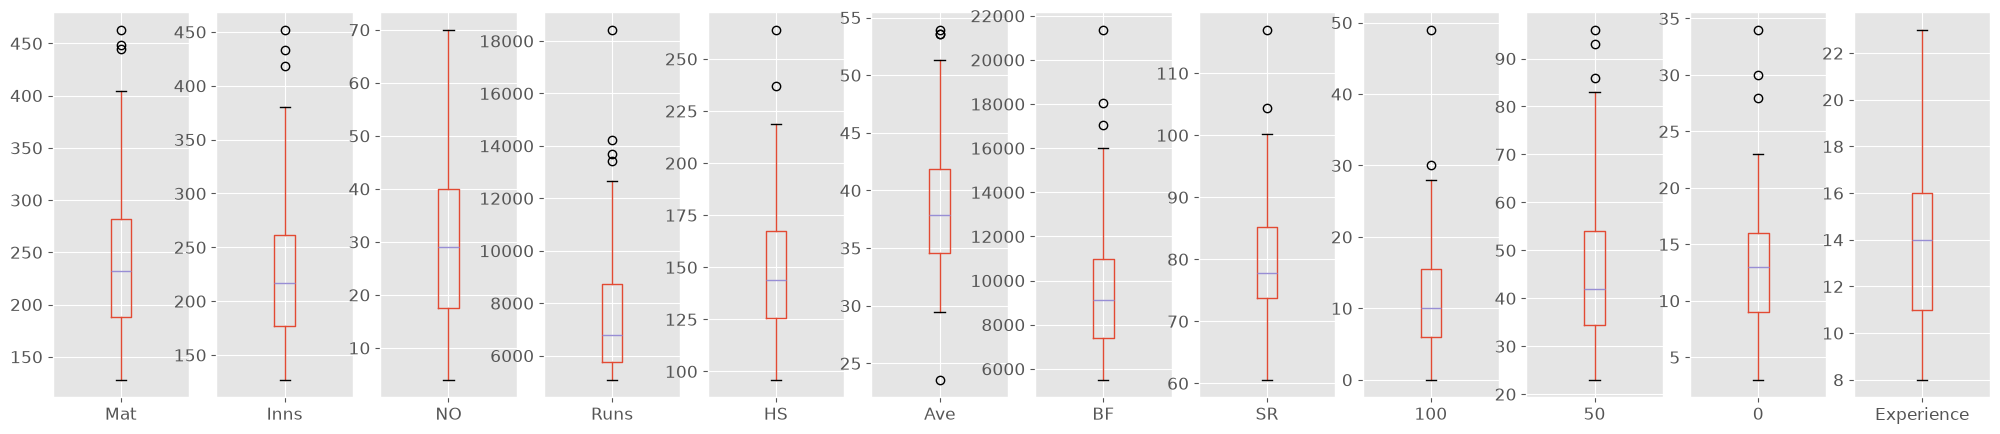

In [56]:
numeric_cols = df_1.select_dtypes(include= np.number).columns.to_list()

fig, axes = plt.subplots(1, len(numeric_cols), figsize=(25, 5))

for ax, col in zip(axes, numeric_cols):
    df_1.boxplot(column=col,ax=ax)
  
    

In [57]:
df_copy = df.copy()

In [58]:
df_copy.drop(columns='Player',inplace=True)
df_copy

,Mat,Inns,NO,Runs,HS,Ave,BF,SR,100,50,0,Experience
0,463,452,41,18426,200,44.83,21367,86.23,49,96,20,23
1,404,380,41,14234,169,41.98,18048,78.86,25,93,15,15
2,375,365,39,13704,164,42.03,17046,80.39,30,82,20,17
3,445,433,18,13430,189,32.36,14725,91.20,28,68,34,22
4,448,418,39,12650,144,33.37,16020,78.96,19,77,28,17
...,...,...,...,...,...,...,...,...,...,...,...,...
74,128,127,13,5134,133,45.03,7908,64.92,11,31,3,16
75,162,149,31,5122,96,43.40,6945,73.75,0,42,6,13
76,197,181,37,5092,120,35.36,6614,76.98,5,26,7,10
77,198,161,33,5088,156,39.75,5504,92.44,6,30,15,11


In [59]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

se = StandardScaler()

df_scaled = se.fit_transform(df_copy)


In [60]:
df_scaled = pd.DataFrame(df_scaled , columns = df_copy.columns)
df_scaled

,Mat,Inns,NO,Runs,HS,Ave,BF,SR,100,50,0,Experience
0,2.955282,3.169333,0.764963,4.262328,1.632443,1.072294,3.681214,0.703152,4.656726,3.050057,1.145837,2.812787
1,2.155179,2.138915,0.764963,2.609117,0.635224,0.587725,2.635385,-0.044139,1.671888,2.865418,0.296671,0.380938
2,1.761908,1.924245,0.625397,2.400099,0.474382,0.596226,2.319651,0.110997,2.293729,2.188406,1.145837,0.988900
3,2.711183,2.897417,-0.840046,2.292041,1.278591,-1.047909,1.588295,1.207091,2.044992,1.326755,3.523501,2.508806
4,2.751866,2.682747,0.625397,1.984430,-0.168986,-0.876185,1.996354,-0.034000,0.925678,1.880674,2.504502,0.988900
...,...,...,...,...,...,...,...,...,...,...,...,...
74,-1.587674,-1.481860,-1.188961,-0.979677,-0.522838,1.106299,-0.559768,-1.457604,-0.069268,-0.950465,-1.741328,0.684919
75,-1.126598,-1.167010,0.067133,-0.984410,-1.713068,0.829159,-0.863213,-0.562275,-1.437319,-0.273453,-1.231828,-0.227024
76,-0.651961,-0.709047,0.485831,-0.996241,-0.941027,-0.537836,-0.967512,-0.234765,-0.815478,-1.258197,-1.061995,-1.138967
77,-0.638400,-0.995274,0.206699,-0.997819,0.217035,0.208570,-1.317278,1.332823,-0.691110,-1.012011,0.296671,-0.834986


In [61]:
me = MinMaxScaler()
df_scaled_1 = me.fit_transform(df_copy)
df_scaled_1 = pd.DataFrame(df_scaled_1 , columns = df_copy.columns)
df_scaled_1

,Mat,Inns,NO,Runs,HS,Ave,BF,SR,100,50,0,Experience
0,1.000000,1.000000,0.560606,1.000000,0.619048,0.700033,1.000000,0.454723,1.000000,1.000000,0.548387,1.000000
1,0.823881,0.778462,0.560606,0.685898,0.434524,0.606190,0.790771,0.324118,0.510204,0.958904,0.387097,0.466667
2,0.737313,0.732308,0.530303,0.646186,0.404762,0.607837,0.727605,0.351232,0.612245,0.808219,0.548387,0.600000
3,0.946269,0.941538,0.212121,0.625656,0.553571,0.289430,0.581290,0.542796,0.571429,0.616438,1.000000,0.933333
4,0.955224,0.895385,0.530303,0.567211,0.285714,0.322687,0.662926,0.325890,0.387755,0.739726,0.806452,0.600000
...,...,...,...,...,...,...,...,...,...,...,...,...
74,0.000000,0.000000,0.136364,0.004046,0.220238,0.706618,0.151548,0.077087,0.224490,0.109589,0.000000,0.533333
75,0.101493,0.067692,0.409091,0.003147,0.000000,0.652947,0.090840,0.233564,0.000000,0.260274,0.096774,0.333333
76,0.205970,0.166154,0.500000,0.000899,0.142857,0.388212,0.069974,0.290803,0.102041,0.041096,0.129032,0.133333
77,0.208955,0.104615,0.439394,0.000599,0.357143,0.532763,0.000000,0.564771,0.122449,0.095890,0.387097,0.200000


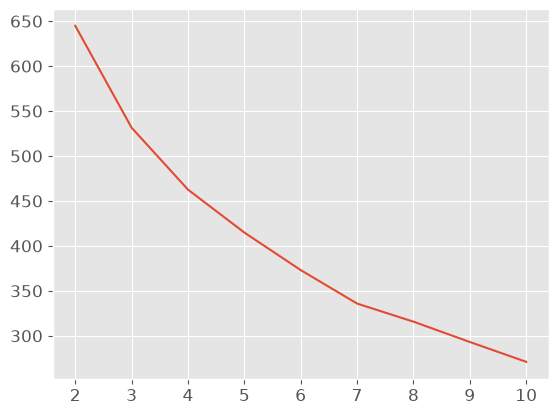

In [62]:
wcss = []

K_range = range(2,11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++', # 
        n_init=20, # how many times k-means run with different initial centroid
        max_iter=150, # max iteration allowed in one run
        random_state=42        
    )

    kmeans.fit(df_scaled)
    wcss.append(kmeans.inertia_) # inertia = sum of sq values (x -mu)
    
plt.plot(K_range, wcss)    
    

Text(0.5, 1.0, 'Silhouette Analysis')

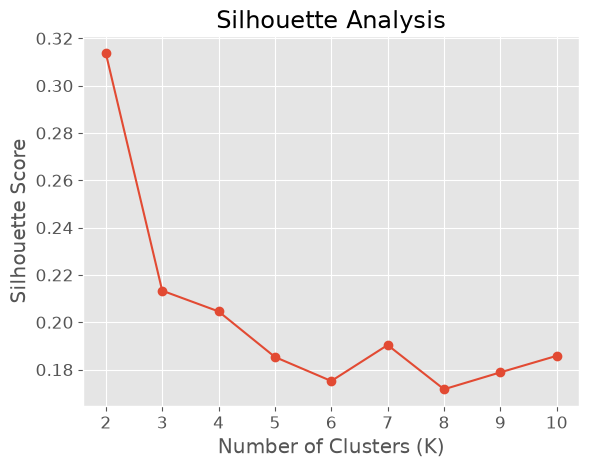

In [63]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=20, # how many times 
        random_state=42
    )

    labels = kmeans.fit_predict(df_scaled)

    score = silhouette_score(df_scaled, labels)

    silhouette_scores.append(score)

# Plot silhouette scores
plt.plot(
    K_range,
    silhouette_scores,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis')

In [64]:
kmodel = KMeans(n_clusters=3, max_iter=150, random_state=42)
kmodel.fit(df_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",150
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 12)","

In [65]:
print(kmodel.labels_)

[2 2 2 2 2 2 2 2 2 2 0 0 1 0 0 0 0 1 1 0 0 0 0 1 1 0 1 1 1 0 0 0 0 1 0 1 1
 1 0 1 1 1 0 1 1 1 0 1 1 1 1 0 1 0 1 1 0 1 0 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1
 1 0 1 1 1]


<Axes: xlabel='Runs', ylabel='Ave'>

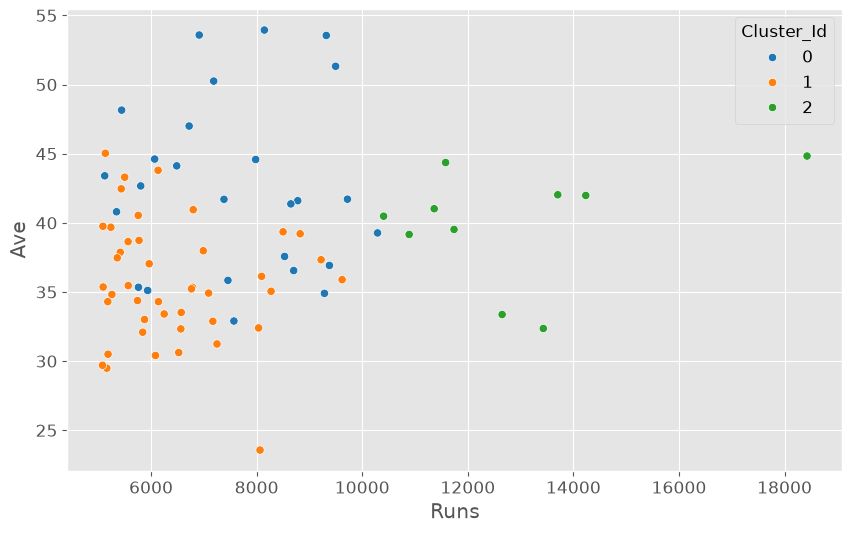

In [71]:
df['Cluster_Id'] = kmodel.labels_

plt.figure(figsize=(10,6))
sns.scatterplot(data=df , x='Runs',y='Ave',hue='Cluster_Id', palette='tab10')

In [67]:
df['Cluster_Id'].value_counts().sort_index()

Cluster_Id
0    26
1    43
2    10
Name: count, dtype: int64

In [68]:
pip install plotly


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [69]:
import plotly.express as px


In [70]:
fig = px.scatter_3d(df , x='Runs',y='Ave',z = 'SR',color='Cluster_Id',hover_name='Player',title='3D Scatter Plot')
fig.update_layout(scene=dict(xaxis_title='Runs',yaxis_title='Average',zaxis_title='Strike Rate'),width=800,height=600)
fig.show()

In [73]:
df['Cluster_Id'].value_counts()

Cluster_Id
1    43
0    26
2    10
Name: count, dtype: int64